# Stable derivative for one parameter, without the LISA response

This example checks SEF's stable derivative for a single parameter, the initial eccentricity `e0`, by comparing the Fisher estimate of its uncertainty with the true likelihood. The notebook:

1. Computes the single-element Fisher matrix $\Gamma$ for `e0` with `deriv_type='stable'`.
2. Turns it into a Gaussian approximation of the 1D likelihood, with standard deviation $\sigma = 1/\sqrt{\Gamma}$.
3. Computes the true 1D likelihood over $\pm 4\sigma$ and compares the two.

No response or noise model is given, so SEF uses the sky-averaged LISA sensitivity curve (`sensitivity_lwa`) on the two polarisations $h_+$ and $h_\times$. This notebook only needs FEW and StableEMRIFisher; `stable_derivative_one_param_with_response.ipynb` does the same through the LISA response.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import few
from few.waveform import FastSchwarzschildEccentricFlux

from stableemrifisher.fisher import StableEMRIFisher
from stableemrifisher.utils import inner_product

use_gpu = False  # set to True to run on an NVIDIA GPU

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")

## Set up StableEMRIFisher

The waveform model is FEW's Schwarzschild eccentric flux model. `mode_selection_threshold` drops the harmonic modes that contribute less than this fraction of the total power. With no `noise_model` or `ResponseWrapper`, SEF logs that it uses the sky-averaged sensitivity curve.

In [2]:
T = 0.1  # observation time, years
dt = 10.0  # sampling interval, seconds

sef = StableEMRIFisher(
    waveform_class=FastSchwarzschildEccentricFlux,
    waveform_class_kwargs=dict(
        inspiral_kwargs=dict(err=1e-11),  # trajectory integrator tolerance
        mode_selector_kwargs=dict(mode_selection_threshold=1e-5),
    ),
    T=T,
    dt=dt,
    deriv_type="stable",
    use_gpu=use_gpu,
)

No noise model or response wrapper provided.
Defaulting to the sky-averaged sensitivity curve


## Compute the Fisher element for `e0`

SEF tries `Ndelta` step sizes from its default grid and keeps the one where the diagonal Fisher element is most stable. `stability_plot=True` plots this search, and `stats_for_nerds=True` prints the chosen step size.

Waveform Generated. SNR: 195.40916807226978
  e0         delta = 7.723e-06   relerr = 1.3e-07   (8 steps)            
Choosing step sizes: 100%|██████████| 8/8 [00:11<00:00,  1.47s/deriv]    


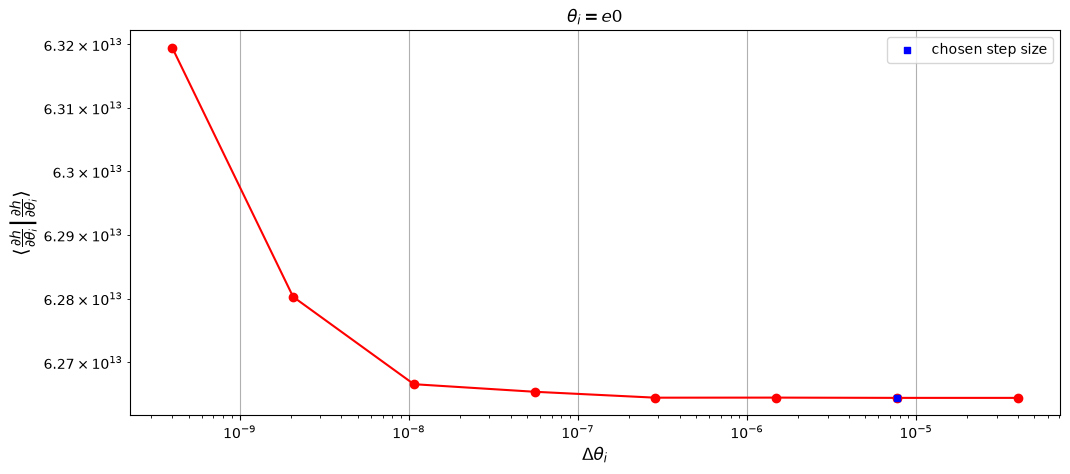

Computing Fisher   : 100%|██████████| 1/1 [00:01<00:00,  1.30s/deriv]    
Calculated Fisher is positive-definite.
Fisher estimate: sigma(e0) = 1.263e-07


In [3]:
wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=10.0,  # secondary mass, solar masses
    a=0.0,  # primary spin
    p0=9.5,  # initial semi-latus rectum
    e0=0.4,  # initial eccentricity
    xI0=1.0,  # cosine of the initial inclination
    dist=0.1,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # initial polar phase
    Phi_r0=0.0,  # initial radial phase
)

param = "e0"

Fisher = sef(
    wave_params,
    param_names=[param],
    der_order=4,
    Ndelta=8,
    stability_plot=True,
    stats_for_nerds=True,
)

sigma = 1 / np.sqrt(Fisher[0, 0])
print(f"Fisher estimate: sigma({param}) = {sigma:.3e}")

## Compare with the true likelihood

The reference ("injected") waveform is the one SEF computed. If the inspiral plunges before the end of the observation, the derivatives are zero-padded at the end; `npad` is the number of padded samples (0 here), and those samples are zeroed in every waveform below so that all of them cover the same span.

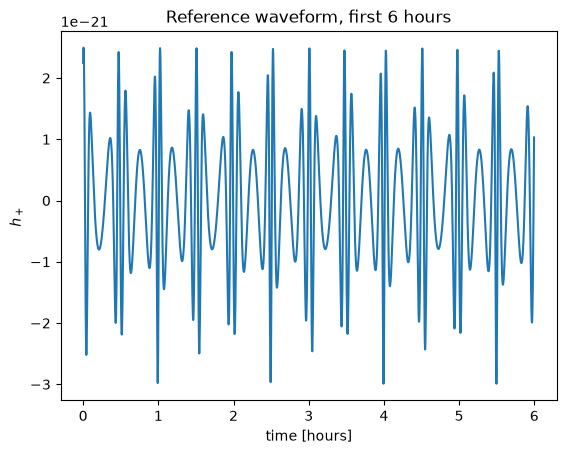

In [4]:
npad = sef.derivative.npad
N = sef.waveform.shape[-1]

reference = sef.waveform.copy()
reference[:, N - npad:] = 0.0

# plot the first 6 hours of the plus polarisation
n_show = int(6 * 3600 / dt)
time_hours = np.arange(n_show) * dt / 3600
plt.plot(time_hours, reference[0, :n_show].get() if use_gpu else reference[0, :n_show])
plt.xlabel("time [hours]")
plt.ylabel(r"$h_+$")
plt.title("Reference waveform, first 6 hours")
plt.show()

Now vary `e0` over $\pm 4\sigma$ around its true value. At each point, generate a template waveform $h$ with the same generator SEF uses and compute the (noise-free) likelihood

$$\mathcal{L} \propto \exp\left[-\tfrac{1}{2}\left(h_{\rm ref} - h \,\middle|\, h_{\rm ref} - h\right)\right].$$

This loop generates 50 waveforms, so it is the slowest step of the notebook.

In [5]:
values = np.linspace(wave_params[param] - 4 * sigma, wave_params[param] + 4 * sigma, 50)

log_like = []
for value in tqdm(values, desc="Likelihood", file=sys.stdout):
    params = dict(sef.wave_params, **{param: value})
    template = sef.derivative.generate(*params.values(), **sef.current_waveform_kwargs)
    template[:, N - npad:] = 0.0
    residual = reference - template
    log_like.append(-0.5 * inner_product(residual, residual, sef.PSD_funcs, dt, use_gpu=use_gpu))

likelihood = np.exp(np.array(log_like) - max(log_like))
gaussian = np.exp(-0.5 * ((values - wave_params[param]) / sigma) ** 2)

Likelihood: 100%|██████████| 50/50 [00:34<00:00,  1.47it/s]


Compare the normalised true likelihood (black) with the Gaussian predicted by the Fisher matrix (red, dashed).

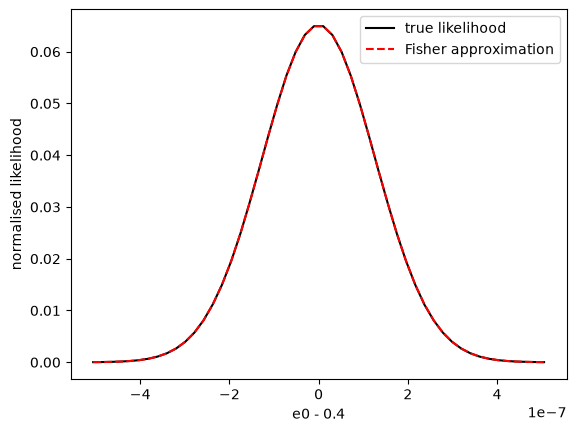

In [6]:
offset = values - wave_params[param]
plt.plot(offset, likelihood / likelihood.sum(), "k", label="true likelihood")
plt.plot(offset, gaussian / gaussian.sum(), "r--", label="Fisher approximation")
plt.xlabel(f"{param} - {wave_params[param]}")
plt.ylabel("normalised likelihood")
plt.legend()
plt.show()

## What this shows

The Fisher matrix describes the likelihood well for `e0` when the two curves overlap. The same check works for any other parameter: change `param` (and, if needed, `Ndelta`) and re-run.